# Task 1: Netflix Content Recommendation System
**Auspify Technologies – Machine Learning Internship**

Objective: suggest similar Netflix titles based on genres, categories and content attributes (*content-based* recommendation).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

df = pd.read_csv("Dataset.csv")
print(df.shape)
df.head()

(8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure"
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Dataset exploration

In [2]:
print(df.dtypes, "\n")
print("Missing values:\n", df.isna().sum(), "\n")
print("Exact duplicates:", df.duplicated().sum())
print("Duplicated titles:", df["title"].duplicated().sum())
print("Directors marked 'Not Given':", (df["director"] == "Not Given").sum(), "out of", len(df))

show_id         object
type            object
title           object
director        object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
dtype: object 

Missing values:
 show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64 

Exact duplicates: 0
Duplicated titles: 3
Directors marked 'Not Given': 2588 out of 8790


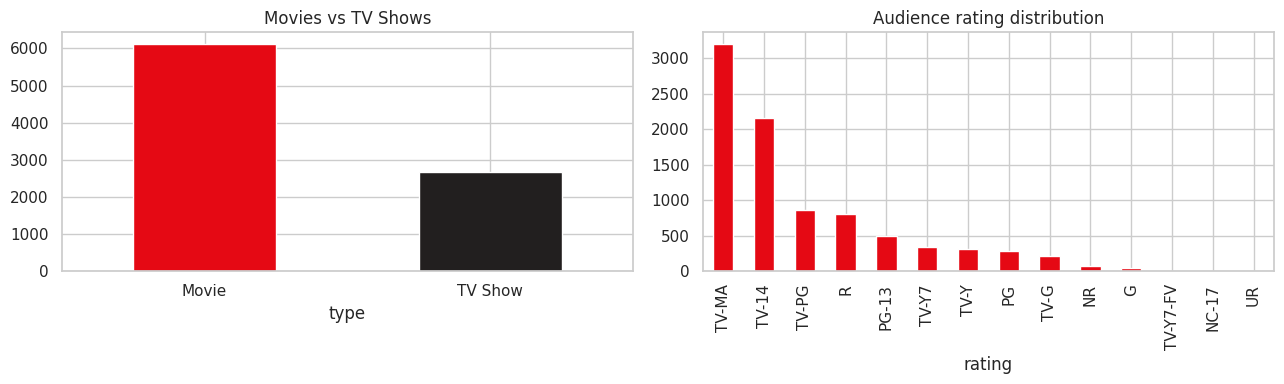

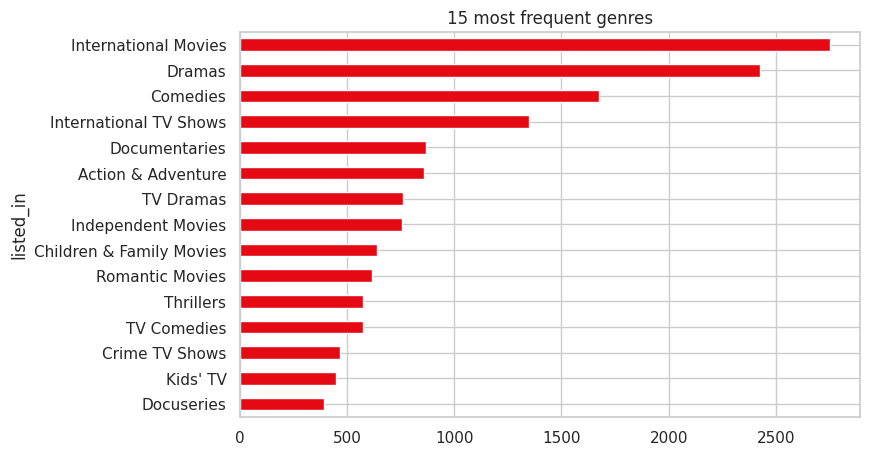

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df["type"].value_counts().plot.bar(ax=axes[0], color=["#e50914", "#221f1f"], rot=0)
axes[0].set_title("Movies vs TV Shows")
df["rating"].value_counts().plot.bar(ax=axes[1], color="#e50914")
axes[1].set_title("Audience rating distribution")
plt.tight_layout(); plt.show()

genres_count = df["listed_in"].str.split(", ").explode().value_counts().head(15)
genres_count.sort_values().plot.barh(figsize=(8, 5), color="#e50914")
plt.title("15 most frequent genres"); plt.show()

**Important observation:** the dataset has **no description column** (synopsis). Recommendations will therefore rely only on metadata: genres, country, director, rating and type. Unknown directors are marked `Not Given` (about 29%); they must be ignored, otherwise all these titles would look "similar" to each other.

## 1.Prepare the features

In [4]:
data = df.copy()

# Cleaning: keep a single copy of duplicated titles
data = data.drop_duplicates(subset="title").reset_index(drop=True)

# Unknown values -> empty string
data["director"] = data["director"].replace("Not Given", "")
data["country"] = data["country"].fillna("")

def to_tokens(text, sep=","):
    """'International Movies, Dramas' -> 'international_movies dramas' (one token per item)."""
    if not text:
        return ""
    return " ".join(
        t.strip().lower().replace(" ", "_").replace("-", "_").replace("'", "")
        for t in text.split(sep) if t.strip()
    )

data["genres_tok"]   = data["listed_in"].apply(to_tokens)
data["country_tok"]  = data["country"].apply(to_tokens)
data["director_tok"] = data["director"].apply(to_tokens)
data["rating_tok"]   = "rating_" + data["rating"].str.lower().str.replace("-", "_")
data["type_tok"]     = "type_" + data["type"].str.lower().str.replace(" ", "_")

# Genres matter most: we repeat them to give them more weight
data["soup"] = (
    data["genres_tok"] + " " + data["genres_tok"] + " "
    + data["type_tok"] + " "
    + data["country_tok"] + " "
    + data["director_tok"] + " "
    + data["rating_tok"]
)
data[["title", "soup"]].head(3)

,title,soup
0,Dick Johnson Is Dead,documentaries documentaries type_movie united_states kirsten_johnson rating_...
1,Ganglands,crime_tv_shows international_tv_shows tv_action_&_adventure crime_tv_shows i...
2,Midnight Mass,tv_dramas tv_horror tv_mysteries tv_dramas tv_horror tv_mysteries type_tv_sh...


## 2. Convert text into a machine-readable format (TF-IDF)
Each title becomes a vector. TF-IDF gives more weight to **rare** tokens (e.g. a niche genre) than to very common ones (e.g. `united_states`).

In [5]:
tfidf = TfidfVectorizer(token_pattern=r"[^\s]+", lowercase=False)
X = tfidf.fit_transform(data["soup"])
print("TF-IDF matrix:", X.shape, "(titles x tokens)")
print("Example tokens:", list(tfidf.get_feature_names_out()[:8]))

TF-IDF matrix: (8787, 5131) (titles x tokens)
Example tokens: ['a._l._vijay', 'a._raajdheep', 'a._salaam', 'a.r._murugadoss', 'aadish_keluskar', 'aamir_bashir', 'aamir_khan', 'aanand_rai']


## 3. Cosine similarity
Since TF-IDF vectors are normalized, the dot product (`linear_kernel`) equals the cosine similarity. We compute it **on demand** for one title, rather than building the full 8,787 x 8,787 matrix (more than 600 MB).

In [6]:
indices = pd.Series(data.index, index=data["title"].str.lower())

def similarity_scores(title):
    idx = indices[title.lower()]
    return linear_kernel(X[idx], X).ravel(), idx

## 4. Generate recommendations

In [7]:
def recommend(title, n=10):
    if title.lower() not in indices:
        # Help: suggest titles with a similar name
        close = data[data["title"].str.contains(title, case=False, regex=False)]["title"].head(5).tolist()
        raise ValueError(f"Title not found: {title!r}. Try: {close}")
    scores, idx = similarity_scores(title)
    top = np.argsort(-scores)
    top = [i for i in top if i != idx][:n]
    out = data.loc[top, ["title", "type", "listed_in", "country", "rating"]].copy()
    out.insert(1, "similarity", scores[top].round(3))
    return out.reset_index(drop=True)

recommend("Stranger Things", 10)

,title,similarity,type,listed_in,country,rating
0,Chilling Adventures of Sabrina,1.000,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,TV-14
1,Helix,0.988,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,TV-MA
2,Nightflyers,0.988,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",United States,TV-MA
3,The Originals,0.758,TV Show,"TV Dramas, TV Horror, TV Mysteries",United States,TV-14
4,Anjaan: Special Crimes Unit,0.757,TV Show,"International TV Shows, TV Horror, TV Mysteries",India,TV-14
5,Manifest,0.751,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,TV-14
6,The 4400,0.751,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,TV-14
7,The Vampire Diaries,0.751,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,TV-14
8,The Messengers,0.751,TV Show,"TV Dramas, TV Mysteries, TV Sci-Fi & Fantasy",United States,TV-14
9,The Haunting of Bly Manor,0.744,TV Show,"TV Dramas, TV Horror, TV Mysteries",United States,TV-MA


In [8]:
recommend("The Irishman", 10)

,title,similarity,type,listed_in,country,rating
0,Gangs of New York,1.000,Movie,Dramas,United States,R
1,The Departed,0.794,Movie,"Dramas, Thrillers",United States,R
2,Hugo,0.687,Movie,"Children & Family Movies, Dramas",United States,PG
3,GoodFellas,0.675,Movie,"Classic Movies, Dramas",United States,R
4,Shutter Island,0.667,Movie,Thrillers,United States,R
5,Mean Streets,0.609,Movie,"Classic Movies, Dramas, Independent Movies",United States,R
6,Who's That Knocking at My Door?,0.609,Movie,"Classic Movies, Dramas, Independent Movies",United States,R
7,Raging Bull,0.566,Movie,"Classic Movies, Dramas, Sports Movies",United States,R
8,Alice Doesn't Live Here Anymore,0.547,Movie,"Classic Movies, Comedies, Dramas",United States,PG
9,Rolling Thunder Revue: A Bob Dylan Story by Martin Scorsese,0.478,Movie,"Documentaries, Music & Musicals",United States,TV-MA


In [9]:
recommend("Narcos", 10)

,title,similarity,type,listed_in,country,rating
0,Marvel's Jessica Jones,1.000,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",United States,TV-MA
1,Queen of the South,1.000,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",United States,TV-MA
2,Marvel's Luke Cage,1.000,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",United States,TV-MA
3,Altered Carbon,1.000,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",United States,TV-MA
4,Marvel's The Defenders,1.000,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",United States,TV-MA
5,Marvel's Iron Fist,1.000,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",United States,TV-MA
6,Shooter,0.978,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",United States,TV-14
7,Person of Interest,0.978,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",United States,TV-14
8,Narcos: Mexico,0.935,TV Show,"Crime TV Shows, TV Action & Adventure, TV Dramas",Mexico,TV-MA
9,Marvel's Daredevil,0.886,TV Show,"Crime TV Shows, TV Action & Adventure",United States,TV-MA


## 5. Evaluate recommendation quality
The dataset contains no user history (ratings, viewings), so a classical precision measure cannot be computed. We use two consistency measures, compared with a random recommendation baseline:

- **Genre overlap** (Jaccard index) between the starting title and its recommendations.
- **Same type** (movie/TV show): share of recommendations with the same type as the starting title.

The further the score is above the baseline, the more useful the system.

In [10]:
rng = np.random.default_rng(42)
K = 10
sample = rng.choice(len(data), size=500, replace=False)
genre_sets = data["listed_in"].apply(lambda s: set(g.strip() for g in s.split(",")))

def jaccard(a, b):
    return len(a & b) / len(a | b)

res = {"model": {"jaccard": [], "same_type": []}, "random": {"jaccard": [], "same_type": []}}
for idx in sample:
    scores = linear_kernel(X[idx], X).ravel()
    scores[idx] = -1
    top = np.argsort(-scores)[:K]
    rand = rng.choice([i for i in range(len(data)) if i != idx], size=K, replace=False)
    for name, picks in (("model", top), ("random", rand)):
        res[name]["jaccard"].append(np.mean([jaccard(genre_sets[idx], genre_sets[j]) for j in picks]))
        res[name]["same_type"].append(np.mean(data.loc[picks, "type"].values == data.loc[idx, "type"]))

summary = pd.DataFrame({k: {m: np.mean(v) for m, v in d.items()} for k, d in res.items()}).T
summary.round(3)

,jaccard,same_type
model,0.905,1.000
random,0.095,0.588


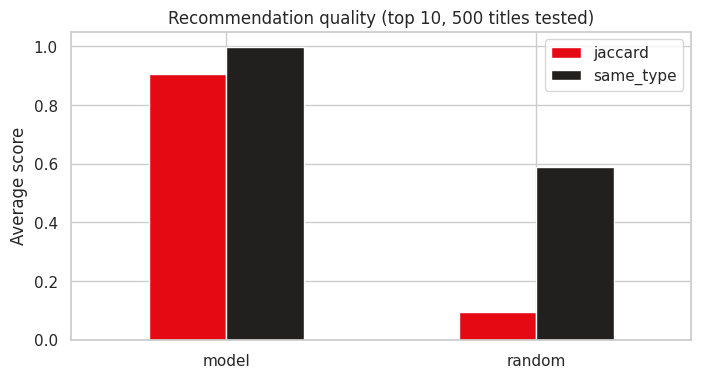

In [11]:
summary.plot.bar(figsize=(8, 4), rot=0, color=["#e50914", "#221f1f"])
plt.title(f"Recommendation quality (top {K}, 500 titles tested)")
plt.ylabel("Average score"); plt.ylim(0, 1.05); plt.show()

## Conclusion and limitations
- The system recommends titles of the **same type with very close genres**, and does clearly better than a random choice.
- **Limitation 1:** without a synopsis, similarity relies on metadata. Two titles with the same genre but different themes will be matched.
- **Limitation 2:** the genre-overlap measure favours the model, since genres are part of its inputs. It shows consistency, not real user satisfaction (which would require viewing data).
- **Improvement ideas:** add a synopsis (TF-IDF on text), weight genres / country / director differently, or combine with collaborative filtering if user data exists.